# Homework · Repeat Purchase Prediction

Machine Learning 2026/27 · NOVA IMS · **Group 41**

**Task:** predict `repeat_purchase_90d`, whether a customer of *Everything & Then Some, Ltd.* buys again within 90 days of a purchase, for every row of `test.csv`. Kaggle scores the predictions with **F1**.

**Final solution of this notebook:** cleaned data → month of purchase as a new feature → median/mode imputation, signed log, robust scaling, one-hot encoding → L1 feature selection → logistic regression, threshold tuned for F1 on a time-ordered validation with a 90-day gap. Expected F1 on new data ≈ 0.80 (honest validation estimate 0.802; Kaggle public score of these predictions 0.804).

**How to run:** put `train.csv`, `test.csv`, `clientes.csv` and `sample_submission.csv` in the folder of this notebook (or in `data/raw/` of the project) and run every cell from the top. It takes about 2 minutes and writes `Homework_Group41_submission.csv` next to the notebook.

**Rule followed throughout:** every transformation that learns from data (imputation, scaling, encoding, feature selection, the model) is fitted **only on training rows**, inside a scikit-learn `Pipeline`. `test.csv` is only cleaned with fixed rules and transformed at the end.

<div class="alert alert-block alert-info">

# Contents<a class="anchor" id="toc"></a>
* [Setup](#setup)
* [1. Import and explore the data](#explore)
* [2. Clean and pre-process the data](#clean)
* [3. Feature selection](#selection)
* [4. Model and performance assessment](#model)
* [5. Summary](#summary)

</div>

# Setup <a class="anchor" id="setup"></a>

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, VarianceThreshold, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)  # unseen categorical levels in a validation fold
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE = "#1779A8", "#C96A00"

RANDOM_STATE = 42
TARGET = "repeat_purchase_90d"
HORIZON = 90  # days: the target looks this far into the future

In [2]:
def find_data_dir(name="train.csv"):
    """The folder with the competition files: this folder, a data/ subfolder, or data/raw/ of a parent folder."""
    here = Path.cwd().resolve()
    candidates = [here, here / "data", here / "data" / "raw"]
    candidates += [parent / "data" / "raw" for parent in here.parents]
    for folder in candidates:
        if (folder / name).exists():
            return folder
    raise FileNotFoundError(f"{name} not found: put the competition files next to this notebook")


DATA_DIR = find_data_dir()
OUTPUT = Path.cwd() / "Homework_Group41_submission.csv"
print("data read from:", DATA_DIR)

data read from: C:\Users\nicob\Desktop\Erasmus\ML_P\ML_Group_41\data\raw


# 1. Import and explore the data <a class="anchor" id="explore"></a>
[Back to contents](#toc)

## 1.1 The files
`ID` identifies the row, so it becomes the index. Columns are grouped by what they describe, following the data description of the brief.

In [3]:
train_raw = pd.read_csv(DATA_DIR / "train.csv", index_col="ID")
test_raw = pd.read_csv(DATA_DIR / "test.csv", index_col="ID")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

GROUPS = {
    "current invoice": ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Total Portes",
                        "Total Desc_ Global", "Total Desc_ Linha", "Custo", "N_ Detalhes",
                        "invoice_count_current_purchase"],
    "current categoricals": ["payment_type", "salesperson", "commercial_zone", "transport_method",
                             "warehouse", "document_series"],
    "history: timing": ["days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count",
                        "prior_mean_gap_days", "prior_std_gap_days"],
    "history: value": ["prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
                       "prior_min_purchase_value", "prior_max_purchase_value"],
    "rolling windows": [f"{kind}_{w}d" for w in [30, 90, 180, 365] for kind in ["purchase_count", "spend"]],
    "identifiers, date, decoy": ["customer_id", "purchase_date", "random_noise"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(test_raw.columns)

print(f"train {train_raw.shape}, test {test_raw.shape}, clientes {clientes.shape}, sample {sample.shape}")
pd.DataFrame({"columns": {g: len(c) for g, c in GROUPS.items()},
              "examples": {g: ", ".join(c[:3]) for g, c in GROUPS.items()}})

train (6534, 38), test (986, 37), clientes (1143, 13), sample (986, 2)


,columns,examples
current invoice,10,"Total a Pagar, Total Bruto, Total Liquido"
current categoricals,6,"payment_type, salesperson, commercial_zone"
history: timing,5,"days_since_previous_purchase, customer_tenure_..."
history: value,5,"prior_total_spend, prior_mean_purchase_value, ..."
rolling windows,8,"purchase_count_30d, spend_30d, purchase_count_90d"
"identifiers, date, decoy",3,"customer_id, purchase_date, random_noise"


## 1.2 The target
F1 is computed on class 1. Predicting 1 for everybody already gives a non-trivial F1: that is the **floor** every model must beat.

In [4]:
rate = train_raw[TARGET].mean()
pd.Series({"rows": len(train_raw), "share of 1 (repeat within 90 days)": round(rate, 3),
           "F1 of 'always 1'": round(f1_score(train_raw[TARGET], np.ones(len(train_raw))), 3)}).to_frame("train")

,train
rows,6534.000
share of 1 (repeat within 90 days),0.559
F1 of 'always 1',0.717


## 1.3 Data quality
Missing values, empty rows and duplicates, and values that cannot be true: negative amounts, counts or day intervals, and amounts of 10⁹ or more.

In [5]:
NUMERIC_RAW = train_raw.columns.drop([TARGET, "customer_id", "purchase_date", "random_noise", *GROUPS["current categoricals"]])

features_raw = train_raw.columns.difference([TARGET, "customer_id"])
empty = train_raw[features_raw].isna().all(axis=1)
print(f"train rows with every feature missing: {empty.sum()} (test: {test_raw[features_raw].isna().all(axis=1).sum()})")
print(f"duplicated train rows: {train_raw.duplicated().sum()} -> {train_raw[~empty].duplicated().sum()} once the empty rows are removed")

quality = pd.DataFrame({
    "missing train %": train_raw.drop(columns=TARGET)[~empty].isna().mean() * 100,
    "missing test %": test_raw.isna().mean() * 100,
    "negative (train+test)": pd.concat([train_raw, test_raw])[NUMERIC_RAW].lt(0).sum(),
    ">= 1e9 (train+test)": pd.concat([train_raw, test_raw])[NUMERIC_RAW].ge(1e9).sum(),
}).fillna(0)
quality[quality.sum(axis=1) > 0].sort_values("missing train %", ascending=False).round(1)

train rows with every feature missing: 65 (test: 0)
duplicated train rows: 10 -> 0 once the empty rows are removed


,missing train %,missing test %,negative (train+test),>= 1e9 (train+test)
prior_std_gap_days,21.8,7.0,0.0,0.0
prior_mean_gap_days,19.2,7.7,18.0,0.0
prior_std_purchase_value,16.2,4.7,0.0,0.0
prior_mean_purchase_value,12.3,5.3,18.0,18.0
days_since_previous_purchase,12.3,5.3,18.0,0.0
prior_max_purchase_value,9.3,2.2,0.0,0.0
prior_min_purchase_value,9.3,2.2,0.0,0.0
transport_method,3.0,3.0,0.0,0.0
payment_type,3.0,3.0,0.0,0.0
spend_365d,3.0,3.0,17.0,17.0


In [6]:
first_purchase = train_raw["prior_purchase_count"] == 0
print("first purchases in train:", first_purchase.sum())
print("missing days_since_previous_purchase among first purchases:",
      train_raw.loc[first_purchase, "days_since_previous_purchase"].isna().mean().round(3))
print("negative values of the day intervals:",
      sorted(set(pd.concat([train_raw, test_raw])[["days_since_previous_purchase", "prior_mean_gap_days"]]
                 .stack().loc[lambda s: s < 0].round(2))))

first purchases in train: 603
missing days_since_previous_purchase among first purchases: 1.0
negative values of the day intervals: [-4.0]


**Reading**
- **65 train rows are empty** except `customer_id` and the target, and they are the cause of all 10 duplicated rows. Test has none.
- **Missing values are of three kinds.** (1) **Structural:** a first purchase (603 in train) has no previous gap or purchase value, so `days_since_previous_purchase` and the `prior_*` statistics are missing by construction; the missing value *means* "no history". (2) **Scattered:** about 3% of the categoricals and of `spend_365d`, in train and test alike. (3) **Corrupted values:** see the next point.
- **Impossible values exist in both files:** day intervals of exactly −4, amounts of 10⁹ (a placeholder, not a purchase) and negative amounts. A single repeated value (−4, 10⁹) is the signature of a placeholder, not of random noise.
- **Action (§2):** drop the empty train rows; turn every impossible value into a missing one with general rules; impute inside the pipeline.

## 1.4 Time and repeated customers
The dates are anonymised, but their order and the intervals between them are preserved.

train: 2015-07-11 -> 2025-02-15
test:  2025-05-24 -> 2026-10-06   (gap of 98 days after train)
customers: 610 in train, 206 in test; 94.5% of test rows belong to a train customer


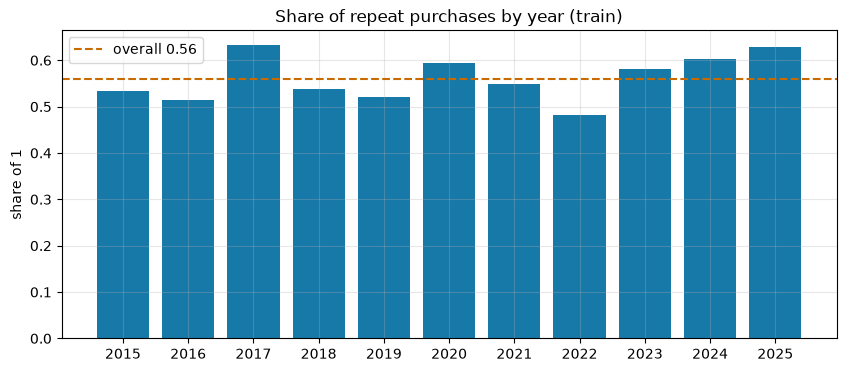

In [7]:
dates_train = pd.to_datetime(train_raw["purchase_date"])
dates_test = pd.to_datetime(test_raw["purchase_date"])
print(f"train: {dates_train.min():%Y-%m-%d} -> {dates_train.max():%Y-%m-%d}")
print(f"test:  {dates_test.min():%Y-%m-%d} -> {dates_test.max():%Y-%m-%d}   "
      f"(gap of {(dates_test.min() - dates_train.max()).days} days after train)")
print(f"customers: {train_raw['customer_id'].nunique()} in train, {test_raw['customer_id'].nunique()} in test; "
      f"{test_raw['customer_id'].isin(train_raw['customer_id']).mean():.1%} of test rows belong to a train customer")

by_year = train_raw.groupby(dates_train.dt.year)[TARGET].agg(["mean", "size"])
fig, ax = plt.subplots()
ax.bar(by_year.index.astype(int).astype(str), by_year["mean"], color=BLUE)
ax.axhline(rate, color=ORANGE, ls="--", label=f"overall {rate:.2f}")
ax.set(title="Share of repeat purchases by year (train)", ylabel="share of 1")
ax.legend()
plt.show()

**How the target is built.** The target asks whether the same customer buys again within 90 days. Inside train we can check it against the customer's next row.

In [8]:
ordered = train_raw[~empty].assign(date=dates_train).sort_values(["customer_id", "date"])
next_gap = ordered.groupby("customer_id")["date"].shift(-1).sub(ordered["date"]).dt.days
has_next = next_gap.notna()
print("train rows whose target equals 'next row of the same customer within 90 days':",
      f"{((next_gap[has_next] <= HORIZON).astype(int) == ordered.loc[has_next, TARGET]).mean():.1%}")

train rows whose target equals 'next row of the same customer within 90 days': 99.7%


**Reading**
- **Test is entirely after train**, with a gap of 98 days: the task is to predict the *future*, which decides the validation scheme (§4.1).
- **The share of repeat purchases drifts by year** (about 0.48 to 0.63): a single validation year would be noisy.
- **94.5% of the test rows come from customers already seen in train**, so the customer's past behaviour, summarised by the history columns, is the main source of information.
- **The target is the customer's next purchase:** in 99.7% of the train rows it equals "the same customer has another row within 90 days". **Consequence for every feature in this notebook:** a feature may use only information available at the time of the purchase. Looking at a customer's *later* rows would reveal the target itself (a leak that gives an almost perfect but useless score), so no feature reads them.

## 1.5 Univariate view
Skewness of the numeric columns (on valid values only) and the levels of the categorical columns.

In [9]:
valid = train_raw[~empty][NUMERIC_RAW]
valid = valid.mask((valid < 0) | (valid >= 1e9))  # exploration only: impossible values hidden
pd.DataFrame({"median": valid.median(), "mean": valid.mean(), "max": valid.max(),
              "skewness": valid.skew(), "share of zeros": valid.eq(0).mean()}).sort_values("skewness", ascending=False).round(2).head(12)

,median,mean,max,skewness,share of zeros
Total Desc_ Global,0.00,0.35,218.49,27.46,0.98
prior_max_purchase_value,1783.24,2946.38,267526.19,21.34,0.00
prior_mean_purchase_value,724.90,957.93,72937.16,21.20,0.00
Total Portes,0.00,1.15,181.06,19.55,0.84
spend_365d,2426.60,5777.74,522933.21,18.55,0.13
prior_mean_gap_days,68.61,96.18,3199.00,9.31,0.00
prior_std_gap_days,50.64,74.14,2212.54,7.77,0.00
days_since_previous_purchase,57.00,101.83,3199.00,6.53,0.00
invoice_count_current_purchase,1.00,1.07,5.00,6.44,0.00
Total Desc_ Linha,13.13,112.47,4103.44,5.92,0.38


In [10]:
CATEGORICAL = GROUPS["current categoricals"]
pd.DataFrame({
    "levels in train": train_raw[CATEGORICAL].nunique(),
    "top level share": train_raw[CATEGORICAL].apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "levels with < 50 rows": train_raw[CATEGORICAL].apply(lambda s: (s.value_counts() < 50).sum()),
    "test rows with a level unseen in train": [(~test_raw[c].dropna().isin(train_raw[c])).sum() for c in CATEGORICAL],
}).round(2)

,levels in train,top level share,levels with < 50 rows,test rows with a level unseen in train
payment_type,9,0.73,5,3
salesperson,9,0.65,4,0
commercial_zone,5,0.97,2,209
transport_method,80,0.18,57,63
warehouse,2,1.00,1,7
document_series,3,0.42,0,0


**Reading**
- **The numeric columns are strongly right-skewed** (skewness up to 27) and several are mostly zeros (global discounts, shipping, short-window spend): a few very large invoices or customers dominate the raw scale. → log transformation and robust scaling for linear and distance models (§2.7).
- **Categoricals:** `warehouse` (100% one level) and `commercial_zone` (97%) are almost constant; `transport_method` has 80 levels, 57 of them with fewer than 50 rows; and **209 test rows have a `commercial_zone` never seen in train**. → one-hot encoding with rare levels grouped and unseen levels sent to the same "infrequent" group (§2.7).

## 1.6 Relationships with the target
Spearman correlation for the numeric columns (robust to the skew), Cramér's V for the categorical ones, and the repeat rate by month of purchase.

In [11]:
def cramers_v(x, y):
    """Association between two categorical variables: 0 = none, 1 = perfect."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


labelled = train_raw[~empty]
spearman = valid.corrwith(labelled[TARGET], method="spearman").sort_values(key=abs, ascending=False)
cramer = pd.Series({c: cramers_v(labelled[c].fillna("missing"), labelled[TARGET]) for c in CATEGORICAL}).sort_values(ascending=False)
display(spearman.head(8).round(3).to_frame("Spearman with target"))
display(cramer.round(3).to_frame("Cramér's V with target"))

,Spearman with target
purchase_count_365d,0.437
prior_mean_gap_days,-0.420
purchase_count_180d,0.406
purchase_count_90d,0.393
spend_365d,0.388
spend_180d,0.370
spend_90d,0.359
prior_purchase_count,0.346


,Cramér's V with target
transport_method,0.285
payment_type,0.234
salesperson,0.201
commercial_zone,0.064
warehouse,0.040
document_series,0.003


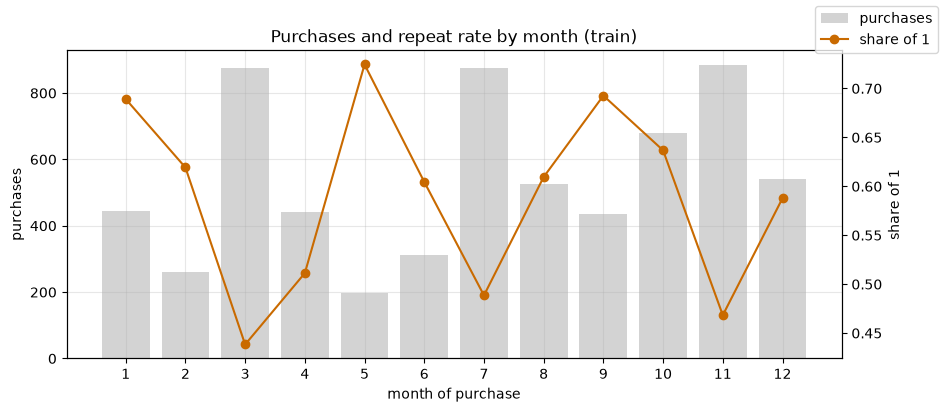

In [12]:
month = dates_train.dt.month
by_month = train_raw.groupby(month)[TARGET].agg(["mean", "size"])
fig, ax1 = plt.subplots()
ax1.bar(by_month.index, by_month["size"], color="lightgrey", label="purchases")
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month["mean"], color=ORANGE, marker="o", label="share of 1")
ax1.set(xticks=range(1, 13), xlabel="month of purchase", ylabel="purchases", title="Purchases and repeat rate by month (train)")
ax2.set_ylabel("share of 1")
ax2.grid(False)
fig.legend(loc="upper right")
plt.show()

In [13]:
corr = valid.corr(method="spearman").abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs >= 0.9].sort_values(ascending=False).round(3).to_frame("|Spearman|").head(12)

,,|Spearman|
Total a Pagar,Total Liquido,1.000
Total Bruto,Total Liquido,0.991
Total a Pagar,Total Bruto,0.991
purchase_count_30d,spend_30d,0.965
prior_std_purchase_value,prior_max_purchase_value,0.923
purchase_count_90d,spend_90d,0.909
prior_purchase_count,prior_total_spend,0.903


**Reading**
- **Frequency and recency are the strongest signals:** purchases in the last 365 / 180 / 90 days (Spearman ≈ 0.4) and the customer's usual gap between purchases (−0.42: customers who buy often come back within 90 days).
- **Among the categoricals,** `transport_method`, `payment_type` and `salesperson` are associated with the target (Cramér's V 0.20–0.29); `document_series` is not (0.003).
- **The repeat rate follows a 4-month cycle:** March, July and November have the most purchases and the **lowest** repeat rate; the months two months before each peak have the highest. A purchase made in a peak month is followed by the next peak more than 90 days later. → the **month of purchase** is a candidate feature (§2.8).
- **Many columns are near-duplicates** (|ρ| ≥ 0.9): the invoice totals among themselves, each rolling count with its spend, total spend with purchase count. → a feature-selection step that removes redundancy (§3).

## 1.7 Identifier-like columns and `random_noise`
`ID`, `customer_id` and `random_noise` are numbers, but that does not make them predictors. Each is tested instead of assumed: does it separate the target (ROC AUC of the column alone; 0.5 = no information) and does it follow time?

In [14]:
ident = labelled.assign(ID=labelled.index, date_order=dates_train[~empty].rank())
pd.DataFrame({
    "ROC AUC alone vs target": {c: roc_auc_score(ident[TARGET], ident[c].fillna(ident[c].median()))
                                for c in ["ID", "customer_id", "random_noise"]},
    "Spearman with date": {c: ident[c].corr(ident["date_order"], method="spearman")
                           for c in ["ID", "customer_id", "random_noise"]},
    "mean in class 0": ident.groupby(TARGET)[["ID", "customer_id", "random_noise"]].mean().loc[0],
    "mean in class 1": ident.groupby(TARGET)[["ID", "customer_id", "random_noise"]].mean().loc[1],
}).round(3)

,ROC AUC alone vs target,Spearman with date,mean in class 0,mean in class 1
ID,0.507,0.011,1.000380e+07,1.000386e+07
customer_id,0.433,-0.022,5.401664e+05,4.804788e+05
random_noise,0.495,0.018,-9.000000e-03,-3.300000e-02


**Reading**
- **`ID`:** no relation with the target (ROC AUC 0.507) or with time. It is a row label: it becomes the index and is never a feature.
- **`customer_id`:** an anonymised code. Its weak relation with the target (0.433) only says *which* customers are frequent buyers; a model would memorise customers instead of learning behaviour, and the number itself has no meaning. It is used only to join `clientes.csv`, never as a feature.
- **`random_noise`:** the same distribution in both classes (ROC AUC 0.495): it carries no information and is dropped.

## 1.8 The optional `clientes.csv`
A customer table, joined through `customer_id`. Which columns could carry information?

In [15]:
print(f"{clientes['customer_id'].nunique()} customers; every train and test customer is in it: "
      f"{train_raw['customer_id'].isin(clientes['customer_id']).all() and test_raw['customer_id'].isin(clientes['customer_id']).all()}")
pd.DataFrame({"missing %": clientes.isna().mean() * 100, "distinct values": clientes.nunique()}).round(1)

1143 customers; every train and test customer is in it: True


,missing %,distinct values
customer_id,0.0,1143
country_or_region,0.0,11
commercial_region,10.0,37
island,50.6,10
municipality,13.9,183
city,47.8,417
postal_area,6.2,271
postal_code,14.9,828
street,52.3,511
address,0.5,1120


In [16]:
joined = labelled.join(clientes.set_index("customer_id"), on="customer_id")
first_year = (dates_train[~empty] - pd.to_timedelta(labelled["customer_tenure_days"], unit="D")).dt.year
display(joined.groupby("country_or_region")[TARGET].agg(["mean", "size"]).query("size >= 100").round(2))
print("customer_since_year later than the first recorded purchase:", (joined["customer_since_year"] > first_year).mean())
print("Spearman of customer_since_year with target:", joined["customer_since_year"].corr(joined[TARGET], method="spearman").round(3),
      "| of customer_tenure_days with target:", joined["customer_tenure_days"].corr(joined[TARGET], method="spearman").round(3))

,mean,size
country_or_region,,
Country CT10: Land of The Final Version,0.57,6256
Country CT5: Land of The Final Version,0.39,194


customer_since_year later than the first recorded purchase: 0.0
Spearman of customer_since_year with target: -0.111 | of customer_tenure_days with target: 0.12


**Reading**
- **The join is complete** (every train and test customer is in the table), but **most columns cannot help**: `customer_type` is empty, `company_name` and `address` are unique per customer (identifiers), and the geography from municipality down to street has hundreds of levels for 610 customers, often missing.
- **Two columns are plausible:** `country_or_region` (repeat rate 0.57 in the main country, 0.39 in the second, which has only 194 rows) and `customer_since_year`. The latter is **never later than the first recorded purchase**, so it does not carry future information, but it tells almost the same as `customer_tenure_days` (Spearman with target −0.11 vs +0.12).
- **Decision taken with the model in §2.8:** these two are tested as a feature group; the table is integrated only if it helps.

## 1.9 Insights and the actions they lead to

| # | Finding | Action |
|---|---|---|
| 1 | 65 empty train rows, cause of all duplicates | drop them (train only) — §2.2 |
| 2 | placeholders (−4 days, 10⁹) and negative amounts in train and test | rule-based: impossible value → missing — §2.3 |
| 3 | exact identities between columns (mean = total ÷ count, …) | rebuild lost values exactly — §2.4 |
| 4 | structural missing values for first purchases, scattered ones elsewhere | imputation inside the pipeline — §2.7 |
| 5 | strong skew, zero-inflated columns | signed log + robust scaling for linear models — §2.7 |
| 6 | dominant, rare and unseen categorical levels | one-hot, rare levels grouped, unseen levels tolerated — §2.7 |
| 7 | 4-month cycle in the repeat rate | month of purchase as a feature — §2.8 |
| 8 | many near-duplicate columns | feature selection — §3 |
| 9 | `ID`, `customer_id`, `random_noise` carry no usable information | never used as features — §3.1 |
| 10 | test is later than train; repeat rate drifts by year; target looks 90 days ahead | time-ordered validation with a 90-day gap; features use only the past — §4.1 |
| 11 | F1 of "always 1" = 0.72 | the floor to beat; tune the threshold — §4.2, §4.4 |

# 2. Clean and pre-process the data <a class="anchor" id="clean"></a>
[Back to contents](#toc)

Two different kinds of step:
- **Cleaning (§2.1–2.4):** deterministic rules, written by hand and identical for train and test. They learn nothing from the data, so applying them to test leaks nothing.
- **Pre-processing (§2.7):** steps that learn from data (medians, scales, encodings). They live in a `Pipeline` and are refitted on the training rows of every fold.

## 2.1 Names and types
English snake_case names for the Portuguese invoice columns, a datetime date, stripped string labels.

In [17]:
COLUMN_MAP = {
    "Total a Pagar": "total_to_pay",        # amount paid by the customer = net + tax
    "Total Bruto": "total_gross",           # before discounts
    "Total Liquido": "total_net",           # after discounts, before tax
    "Total Imp_": "total_tax",              # VAT
    "Total Portes": "total_shipping",       # shipping (not part of total_to_pay)
    "Total Desc_ Global": "discount_global",
    "Total Desc_ Linha": "discount_line",
    "Custo": "cost",                        # cost of goods for the company
    "N_ Detalhes": "n_lines",               # number of product lines on the invoice
}
WINDOWS = [30, 90, 180, 365]
DAY_COLS = ["days_since_previous_purchase", "customer_tenure_days", "prior_mean_gap_days", "prior_std_gap_days"]
COUNT_COLS = ["n_lines", "invoice_count_current_purchase", "prior_purchase_count"] + [f"purchase_count_{w}d" for w in WINDOWS]
AMOUNT_COLS = (["total_to_pay", "total_gross", "total_net", "total_tax", "total_shipping", "discount_global",
                "discount_line", "cost", "prior_total_spend", "prior_mean_purchase_value", "prior_std_purchase_value",
                "prior_min_purchase_value", "prior_max_purchase_value"] + [f"spend_{w}d" for w in WINDOWS])
PLACEHOLDER = 1e9  # value used in the raw data in place of a real amount
TOL = 0.01         # one cent / a hundredth of a day: tolerance for float comparisons


def rename_and_type(df):
    """English snake_case names, datetime date, stripped string categoricals."""
    df = df.rename(columns=COLUMN_MAP)
    df["purchase_date"] = pd.to_datetime(df["purchase_date"])
    for col in CATEGORICAL:
        df[col] = df[col].astype("str").str.strip()
    return df

## 2.2 Empty rows
The 65 train rows with every feature missing carry only a customer and a target: nothing a model can learn from, and they cause all the duplicates. They are removed from **train only**; test has none, and no test row may ever be removed.

In [18]:
def drop_empty_rows(df):
    """Remove rows where every feature is missing (train only). Returns the frame and the number dropped."""
    features = df.columns.difference([TARGET, "customer_id"])
    is_empty = df[features].isna().all(axis=1)
    return df[~is_empty], int(is_empty.sum())

## 2.3 Impossible values → missing
General domain rules, not hard-coded values: a day interval, count or amount cannot be negative; 10⁹ is a placeholder, not a purchase; a customer's mean purchase must equal total ÷ count; the maximum purchase and the 365-day spend cannot exceed the total spend; the 365-day spend cannot be lower than the 180-day one. An impossible value becomes `NaN`, to be imputed later like any other gap.

In [19]:
def invalid_value_rules(df):
    """List of (rule, column, mask). True in the mask = impossible value, to be set to NaN."""
    rules = []
    for col in DAY_COLS:
        rules.append(("negative day interval", col, df[col] < 0))
    for col in COUNT_COLS:
        rules.append(("negative count", col, df[col] < 0))
    for col in AMOUNT_COLS:
        rules.append(("placeholder 1e9", col, df[col] >= PLACEHOLDER))
        rules.append(("negative amount", col, df[col] < 0))
    mean, total, count = df["prior_mean_purchase_value"], df["prior_total_spend"], df["prior_purchase_count"]
    expected_mean = total / count.where(count > 0)
    rules.append(("mean != total / count", "prior_mean_purchase_value",
                  expected_mean.notna() & ~np.isclose(mean, expected_mean, rtol=1e-4, atol=TOL)))
    rules.append(("max > total spend", "prior_max_purchase_value", df["prior_max_purchase_value"] > total + TOL))
    rules.append(("365d spend > total spend", "spend_365d", df["spend_365d"] > total + TOL))
    rules.append(("365d spend < 180d spend", "spend_365d", df["spend_365d"] < df["spend_180d"] - TOL))
    return rules


def set_invalid_to_nan(df):
    """Apply every rule in order; the log counts only cells that were not already NaN."""
    df = df.copy()
    log = []
    for rule, col, mask in invalid_value_rules(df):
        hit = mask & df[col].notna()
        df.loc[hit, col] = np.nan
        log.append((rule, col, int(hit.sum())))
    return df, pd.DataFrame(log, columns=["rule", "column", "cells"])

## 2.4 Rebuilding values from exact identities
Some columns are tied by exact relations (e.g. mean = total ÷ count; for a first repeat purchase, days since the previous one = tenure). On complete rows these identities hold in 100% of the cases, so a value lost in §2.3 can be **rebuilt exactly** instead of imputed.

In [20]:
def rebuild_from_identities(df):
    """Fill NaNs that an exact identity gives back. Returns the frame and a log of cells filled."""
    df = df.copy()
    log = []

    def fill(col, rule, values, applies):
        hit = df[col].isna() & applies & values.notna()
        df.loc[hit, col] = values[hit]
        log.append((rule, col, int(hit.sum())))

    count, total, tenure = df["prior_purchase_count"], df["prior_total_spend"], df["customer_tenure_days"]
    fill("prior_mean_purchase_value", "total / count", total / count.where(count > 0), count >= 1)
    fill("prior_max_purchase_value", "max = total (count = 1)", total, count == 1)
    fill("days_since_previous_purchase", "days since = tenure (count = 1)", tenure, count == 1)
    fill("days_since_previous_purchase", "tenure - (count-1) x gap",
         (tenure - (count - 1) * df["prior_mean_gap_days"]).round(), count >= 2)
    fill("prior_mean_gap_days", "(tenure - days since) / (count-1)",
         (tenure - df["days_since_previous_purchase"]) / (count - 1), count >= 2)
    fill("spend_365d", "spend 365d = spend 180d (same counts)", df["spend_180d"],
         df["purchase_count_365d"] == df["purchase_count_180d"])
    fill("spend_365d", "spend 365d = total (all in 365d)", total, df["purchase_count_365d"] == count)
    return df, pd.DataFrame(log, columns=["rule", "column", "cells"])

## 2.5 Cleaning train and test
`clean` chains §2.1, §2.3 and §2.4 and never drops a row. The table shows how many cells each rule changed in each file.

In [21]:
def clean(df):
    """Deterministic cleaning, identical for train and test. Never drops rows."""
    df = rename_and_type(df)
    df, _ = set_invalid_to_nan(df)
    df, _ = rebuild_from_identities(df)
    return df


train_kept, n_empty = drop_empty_rows(train_raw)
train = clean(train_kept)
test = clean(test_raw)

logs = {}
for name, frame in [("train", rename_and_type(train_kept)), ("test", rename_and_type(test_raw))]:
    invalid, log_invalid = set_invalid_to_nan(frame)
    _, log_rebuilt = rebuild_from_identities(invalid)
    logs[name] = pd.concat([log_invalid.assign(step="impossible -> NaN"), log_rebuilt.assign(step="rebuilt")])
changes = logs["train"].merge(logs["test"], on=["step", "rule", "column"], suffixes=(" train", " test"))
display(changes[changes[["cells train", "cells test"]].sum(axis=1) > 0].set_index(["step", "rule", "column"]))

# Checks: test keeps every row; same columns; cleaning is idempotent; nothing impossible is left
assert len(test) == len(test_raw) and list(train.columns.drop(TARGET)) == list(test.columns)
assert clean(train_kept).equals(train) and set_invalid_to_nan(pd.concat([train, test]))[1]["cells"].sum() == 0
print(f"train {train_raw.shape} -> {train.shape} ({n_empty} empty rows dropped); test {test_raw.shape} -> {test.shape}")

cells train  \
step              rule                                  column                                      
impossible -> NaN negative day interval                 days_since_previous_purchase           16   
                                                        prior_mean_gap_days                    16   
                  placeholder 1e9                       prior_mean_purchase_value              16   
                  negative amount                       prior_mean_purchase_value              16   
                  placeholder 1e9                       spend_365d                             15   
                  negative amount                       spend_365d                             15   
                  mean != total / count                 prior_mean_purchase_value              46   
                  max > total spend                     prior_max_purchase_value               45   
                  365d spend > total spend              spend_365d                             39   
rebuilt           total / count                         prior_mean_purchase_value             272   
                  max = total (count = 1)               prior_max_purchase_value                3   
                  days since = tenure (count = 1)       days_since_previous_purchase           22   
                  tenure - (count-1) x gap              days_since_previous_purchase          179   
                  (tenure - days since) / (count-1)     prior_mean_gap_days                   203   
                  spend 365d = spend 180d (same counts) spend_365d                             80   
                  spend 365d = total (all in 365d)      spend_365d                             28   

                                                                                      cells test  
step              rule                                  column                                    
impossible -> NaN negative day interval                 days_since_previous_purchase           2  
                                                        prior_mean_gap_days                    2  
                  placeholder 1e9                       prior_mean_purchase_value              2  
                  negative amount                       prior_mean_purchase_value              2  
                  placeholder 1e9                       spend_365d                             2  
                  negative amount                       spend_365d                             2  
                  mean != total / count                 prior_mean_purchase_value              7  
                  max > total spend                     prior_max_purchase_value               6  
                  365d spend > total spend              spend_365d                             7  
rebuilt           total / count                         prior_mean_purchase_value             41  
                  max = total (count = 1)               prior_max_purchase_value               0  
                  days since = tenure (count = 1)       days_since_previous_purchase           1  
                  tenure - (count-1) x gap              days_since_previous_purchase          31  
                  (tenure - days since) / (count-1)     prior_mean_gap_days                   32  
                  spend 365d = spend 180d (same counts) spend_365d                             4  
                  spend 365d = total (all in 365d)      spend_365d                             1

train (6534, 38) -> (6469, 38) (65 empty rows dropped); test (986, 37) -> (986, 37)


**What is still missing after cleaning** is left to the imputation inside the pipeline (§2.7). Most of it is **structural**: a first purchase has no previous gap or purchase value.

In [22]:
left = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum(),
                     "train, first purchases": train[train["prior_purchase_count"] == 0].isna().sum()}).fillna(0).astype(int)
left[left[["train", "test"]].sum(axis=1) > 0].sort_values("train", ascending=False)

,train,test,"train, first purchases"
prior_std_gap_days,1413,69,603
prior_mean_gap_days,1056,46,603
prior_std_purchase_value,1048,46,603
prior_max_purchase_value,645,28,603
days_since_previous_purchase,611,22,603
prior_min_purchase_value,603,22,603
prior_mean_purchase_value,603,22,603
transport_method,196,30,23
payment_type,195,30,19
warehouse,195,30,13


## 2.6 How every decision below is measured
Each choice from here on (new features, `clientes.csv`, feature selection, model, threshold) is decided on the **same validation scheme**, justified in §4.1: **time-ordered cross-validation**, 3 yearly validation blocks (2022, 2023, 2024 → 2025-02), each model trained only on purchases **more than 90 days before** the block. Two pipelines are compared **fold by fold** on ROC AUC (independent of the threshold).

In [23]:
X_full = train.drop(columns=[TARGET])  # identifiers and date are needed to build features, then dropped
y = train[TARGET]
X_test_full = test.copy()
ALWAYS_DROP = ["customer_id", "purchase_date", "random_noise"]


def time_splits(dates, val_starts, gap_days=HORIZON):
    """Expanding-window splits: fold k validates on [start_k, start_k+1) and trains on rows before start_k - gap."""
    dates = pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    starts = list(pd.to_datetime(val_starts)) + [dates.max() + pd.Timedelta(days=1)]
    for start, end in zip(starts[:-1], starts[1:]):
        yield (np.flatnonzero(dates < start - pd.Timedelta(days=gap_days)),
               np.flatnonzero((dates >= start) & (dates < end)))


FOLDS = list(time_splits(X_full["purchase_date"], ["2022-01-01", "2023-01-01", "2024-01-01"]))


def evaluate(model, splits=FOLDS, X=X_full):
    """Refit a fresh copy on each training fold. Returns per-fold ROC AUC and the out-of-fold probabilities."""
    aucs, oof = [], pd.Series(np.nan, index=y.index)
    for tr, va in splits:
        proba = clone(model).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
        oof.iloc[va] = proba
        aucs.append(roc_auc_score(y.iloc[va], proba))
    return np.array(aucs), oof


def compare(pipelines, reference):
    """ROC AUC of each pipeline and its difference from the reference, fold by fold."""
    scores = {name: evaluate(p)[0] for name, p in pipelines.items()}
    rows = {}
    for name, s in scores.items():
        diff = s - scores[reference]
        rows[name] = {"ROC AUC": s.mean(), "fold 1 / 2 / 3": " / ".join(f"{v:.3f}" for v in s),
                      "diff vs reference": diff.mean(), "folds better": f"{(diff > 0).sum()}/{len(s)}"}
    return pd.DataFrame(rows).T.sort_values("ROC AUC", ascending=False)


pd.DataFrame([{"fold": k + 1, "train rows": len(tr), "train until": f"{X_full['purchase_date'].iloc[tr].max():%Y-%m-%d}",
               "validation": f"{X_full['purchase_date'].iloc[va].min():%Y-%m-%d} -> {X_full['purchase_date'].iloc[va].max():%Y-%m-%d}",
               "validation rows": len(va), "share of 1": y.iloc[va].mean().round(3)}
              for k, (tr, va) in enumerate(FOLDS)]).set_index("fold")

,train rows,train until,validation,validation rows,share of 1
fold,,,,,
1,4004,2021-10-02,2022-01-01 -> 2022-12-29,628,0.481
2,4705,2022-10-02,2023-01-01 -> 2023-12-31,767,0.581
3,5403,2023-10-02,2024-01-01 -> 2025-02-15,835,0.605


## 2.7 The pre-processing pipeline

| Step | Numeric columns | Categorical columns | Why |
|---|---|---|---|
| Imputation | training median | training mode | robust to the skew; in our project experiments (not repeated here to keep the notebook short) other plans (mean, zero, KNN, iterative, missing indicators) were within 0.004 ROC AUC, so the simplest is kept |
| Transformation | signed `log1p` | – | the amounts and counts are strongly right-skewed (§1.5); the log stops a few huge invoices from dominating a linear model. It equals `log1p` on non-negative columns |
| Scaling | `RobustScaler` (median / IQR) | – | logistic regression and KNN need comparable scales; the robust version is not driven by the remaining extremes |
| Encoding | – | one-hot; levels with < 50 training rows grouped as "infrequent" | many rare levels (§1.5); unseen test levels go to the infrequent group instead of raising an error |

**Outliers:** no row is removed. The extreme values are real large customers (and test rows cannot be removed); the log transformation already limits their weight.

Tree models get the same imputation and encoding but **no** log or scaling: a monotonic transformation does not change their splits.

In [24]:
def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def preprocessing(linear=True):
    """Imputation, (log + robust scaling for linear / distance models), one-hot encoding."""
    numeric = [("impute", SimpleImputer(strategy="median"))]
    if linear:
        numeric += [("transform", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                    ("scale", RobustScaler())]
    categorical = [("impute", SimpleImputer(strategy="most_frequent")),
                   ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50, sparse_output=False))]
    return ColumnTransformer([("num", Pipeline(numeric), make_column_selector(dtype_include="number")),
                              ("cat", Pipeline(categorical), make_column_selector(dtype_exclude="number"))])


def pipeline(features, model, linear=True, select=None):
    """features (no learning) -> pre-processing -> optional selection -> model."""
    steps = [("features", FunctionTransformer(features)), ("prep", preprocessing(linear))]
    if select is not None:
        steps.append(("select", select))
    return Pipeline(steps + [("model", model)])

## 2.8 New features and `clientes.csv`
Each candidate group comes from a finding of §1 and is computed **from its own row only** (and the static customer table), so it can be built before the split without leaking. Each is added on its own to the base set and compared fold by fold, with logistic regression as the measuring instrument.

| Group | New columns | Hypothesis (from §1) |
|---|---|---|
| `month` | month of purchase (categorical) | repeat rate follows a 4-month cycle (§1.6) |
| `recency` | days since last purchase ÷ usual gap | a customer late with respect to their own rhythm is less likely to come back |
| `trend` | share of the last-365-day purchases and spend that fall in the last 90 days | a customer speeding up comes back |
| `invoice` | margin, discount share | invoice profile; discounts relate to the target (§1.6) |
| `clientes` | years the customer existed before their first recorded purchase; country | seniority and region (§1.8) |

In [25]:
def safe_div(a, b):
    return (a / b.where(b != 0)).astype(float)


CLIENTES = clientes.set_index("customer_id")
FEATURE_GROUPS = {
    "month": lambda df: df.assign(purchase_month=df["purchase_date"].dt.month.astype(str)),
    "recency": lambda df: df.assign(recency_ratio=safe_div(df["days_since_previous_purchase"], df["prior_mean_gap_days"])),
    "trend": lambda df: df.assign(count_share_90_365=safe_div(df["purchase_count_90d"], df["purchase_count_365d"]),
                                  spend_share_90_365=safe_div(df["spend_90d"], df["spend_365d"])),
    "invoice": lambda df: df.assign(margin=1 - safe_div(df["cost"], df["total_net"]),
                                    discount_share=safe_div(df["discount_line"] + df["discount_global"], df["total_gross"])),
    "clientes": lambda df: df.assign(
        years_before_first_purchase=(df["purchase_date"] - pd.to_timedelta(df["customer_tenure_days"], unit="D")).dt.year
        - df["customer_id"].map(CLIENTES["customer_since_year"]),
        country=df["customer_id"].map(CLIENTES["country_or_region"]).astype(str)),
}


def with_groups(*groups):
    """Feature function: add the given groups, then drop identifiers, raw date and the decoy."""
    def build(df):
        for g in groups:
            df = FEATURE_GROUPS[g](df)
        return df.drop(columns=[c for c in ALWAYS_DROP if c in df.columns])
    return build


logistic = LogisticRegression(max_iter=2000)
candidates = {"base (no new feature)": pipeline(with_groups(), logistic)}
candidates |= {f"+ {g}": pipeline(with_groups(g), logistic) for g in FEATURE_GROUPS}
candidates["+ month + recency"] = pipeline(with_groups("month", "recency"), logistic)
compare(candidates, "base (no new feature)").style.format({"ROC AUC": "{:.4f}", "diff vs reference": "{:+.4f}"})

,ROC AUC,fold 1 / 2 / 3,diff vs reference,folds better
+ month + recency,0.7856,0.768 / 0.792 / 0.797,+0.0026,2/3
+ month,0.7851,0.767 / 0.791 / 0.797,+0.0021,2/3
+ clientes,0.7842,0.779 / 0.791 / 0.782,+0.0012,3/3
+ invoice,0.7837,0.779 / 0.789 / 0.783,+0.0007,3/3
base (no new feature),0.7830,0.778 / 0.789 / 0.782,+0.0000,0/3
+ recency,0.7830,0.779 / 0.788 / 0.782,-0.0001,1/3
+ trend,0.7828,0.778 / 0.789 / 0.782,-0.0002,0/3


**Reading** (differences in ROC AUC against the base set, same 3 folds)
- **Every gain is small** (at most +0.003). Most groups repeat information the model already has: the recency ratio and the activity trend are combinations of history and rolling-window columns that are already in.
- **The month gives the largest single gain** (+0.0021) and has a clear mechanism, the 4-month cycle of §1.6. Adding the recency ratio on top changes almost nothing (+0.0005). **Decision: add the month only.** (In our project experiments on 8 half-year folds the month was also the only group that helped, for both a linear and a tree model.)
- **`clientes.csv` is not integrated.** Its gain (+0.0012) is half of the month's and inside the fold-to-fold variation; it would add a join on a table that is a snapshot of today, for information that `customer_tenure_days` already carries (§1.8). The invoice ratios (margin, discount share) are not kept for the same reason.

# 3. Feature selection <a class="anchor" id="selection"></a>
[Back to contents](#toc)

## 3.1 Identifier-like columns, treated critically

| Column | Decision | Evidence |
|---|---|---|
| `ID` | index only, never a feature | no relation with target (ROC AUC 0.507) or time (§1.7) |
| `customer_id` | not a feature; used only for the join and the checks of §1 | an arbitrary code: a model would memorise customers, not behaviour (§1.7) |
| `purchase_date` | the raw date is not a feature; only the **month** is derived from it | test is later than train: a model on absolute dates would extrapolate outside the training range |
| `random_noise` | dropped | same distribution in both classes (ROC AUC 0.495, §1.7) |
| `document_series`, `warehouse`, `commercial_zone` | left to the selection step | no association (V = 0.003) or almost constant (§1.5–1.6): the selection decides, and §3.3 shows it drops all three |

The first four never reach the model: the feature function drops them (`ALWAYS_DROP`).

## 3.2 Strategy
The starting set is every cleaned column + the month (§2.8): after one-hot encoding, about 84 columns. Three families of methods from class are compared, **each refitted inside every training fold** (a selection that reads the target and is fitted on all rows would leak):

| Family | Method | What it asks |
|---|---|---|
| Filter | variance > 0.01 | does the column vary at all? |
| Filter | mutual information, best 35 | how much does each column alone say about the target? |
| Wrapper | recursive feature elimination (RFE) to 35 columns | which columns does a logistic regression need, removing the weakest 10% at a time? |
| Embedded | L1-penalised logistic regression (`C` = 0.05, 0.2) | which coefficients does an L1 penalty keep away from exactly 0? |

The selection step sits between the pre-processing and the model, so it works on the encoded columns.

In [26]:
BASE_FEATURES = with_groups("month")


def scaled_l1(C):
    """L1 logistic regression on standardised columns: its coefficients are comparable only after scaling."""
    return make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=5000))


L1_COEF = "named_steps.logisticregression.coef_"
selectors = {
    "all features": None,
    "filter: variance > 0.01": VarianceThreshold(0.01),
    "filter: mutual information, best 35": SelectKBest(lambda X, t: mutual_info_classif(X, t, random_state=RANDOM_STATE), k=35),
    "wrapper: RFE 35": RFE(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                           n_features_to_select=35, step=0.1, importance_getter=L1_COEF),
    "embedded: L1, C = 0.2": SelectFromModel(scaled_l1(0.2), importance_getter=L1_COEF),
    "embedded: L1, C = 0.05": SelectFromModel(scaled_l1(0.05), importance_getter=L1_COEF),
}
selection_runs = {name: pipeline(BASE_FEATURES, logistic, select=s) for name, s in selectors.items()}
selection_board = compare(selection_runs, "all features")
selection_board["columns kept (all train)"] = {
    name: int(p.fit(X_full, y).named_steps["select"].get_support().sum()) if selectors[name] is not None
    else p.fit(X_full, y).named_steps["prep"].transform(BASE_FEATURES(X_full.head())).shape[1]
    for name, p in selection_runs.items()}
selection_board.style.format({"ROC AUC": "{:.4f}", "diff vs reference": "{:+.4f}"})

,ROC AUC,fold 1 / 2 / 3,diff vs reference,folds better,columns kept (all train)
"embedded: L1, C = 0.05",0.7958,0.779 / 0.807 / 0.801,+0.0106,3/3,25
"embedded: L1, C = 0.2",0.7948,0.779 / 0.805 / 0.800,+0.0097,3/3,27
wrapper: RFE 35,0.7880,0.770 / 0.799 / 0.795,+0.0029,2/3,35
filter: variance > 0.01,0.7861,0.768 / 0.792 / 0.798,+0.0010,3/3,77
all features,0.7851,0.767 / 0.791 / 0.797,+0.0000,0/3,84
"filter: mutual information, best 35",0.7832,0.778 / 0.777 / 0.794,-0.0020,1/3,35


**Reading**
- **L1 selection is the only method that clearly improves the model:** with `C = 0.05` it keeps **25 of 84** encoded columns and gains **+0.0106 ROC AUC, on all 3 folds**. With `C = 0.2` (27 columns) the gain is almost the same: the result does not hinge on the exact value.
- **Why it works:** many columns are near-duplicates (§1.6). With all of them, the logistic regression spreads the weight over copies of the same information and its coefficients are unstable; L1 keeps one representative and sets the others to exactly 0. It acts as a regularisation.
- **The filters do not help:** removing near-constant columns is neutral (+0.001), and mutual information *loses* (−0.002), because it scores each column alone and drops the month levels, which are useful only together.
- **RFE is positive but smaller** (+0.003 with 35 columns).
- **Decision: L1 selection with `C = 0.05`**, refitted on whatever rows the pipeline is trained on. What is fixed is the *strategy*, not a list of columns.

## 3.3 The final feature set
The columns the L1 step keeps when it is fitted on all training rows, with the sign and size of their coefficient in the final model (numeric columns are on a robust scale, one-hot columns are 0/1: compare signs and rough order, not exact sizes).

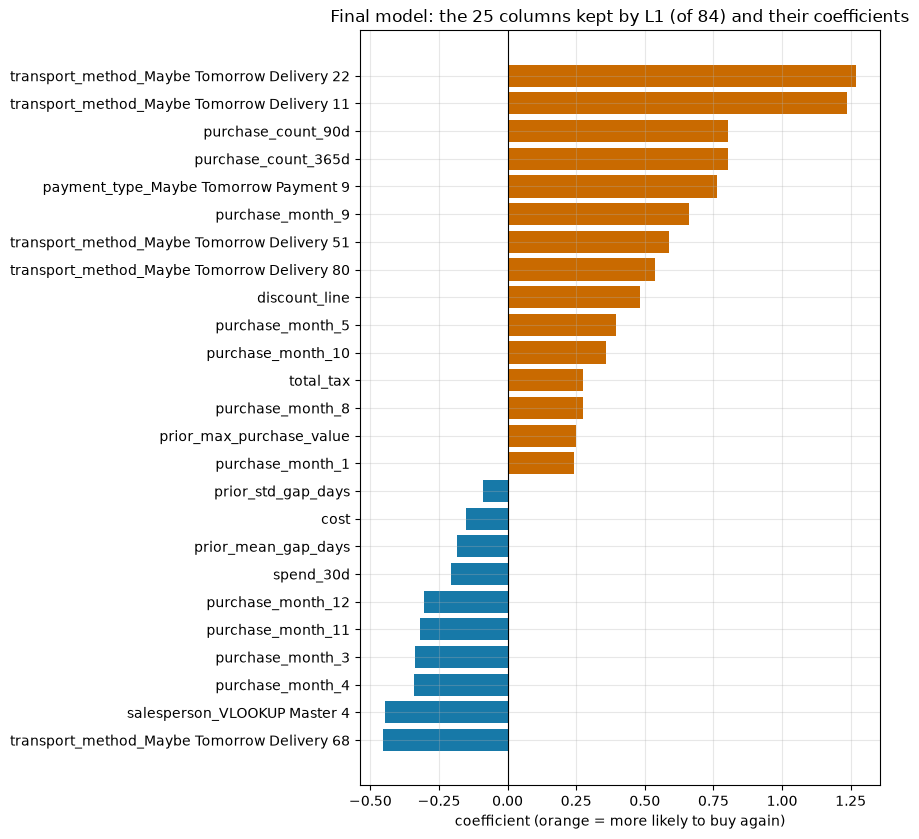

source columns with no encoded column kept (22 of 35): total_to_pay, total_gross, total_net, total_shipping, discount_global, n_lines, invoice_count_current_purchase, days_since_previous_purchase, customer_tenure_days, prior_purchase_count, prior_total_spend, prior_mean_purchase_value, prior_std_purchase_value, prior_min_purchase_value, purchase_count_30d, spend_90d, purchase_count_180d, spend_180d, spend_365d, commercial_zone, warehouse, document_series


,transport_method_Maybe Tomorrow Delivery 22,transport_method_Maybe Tomorrow Delivery 11,purchase_count_90d,purchase_count_365d,payment_type_Maybe Tomorrow Payment 9,purchase_month_9,transport_method_Maybe Tomorrow Delivery 51,transport_method_Maybe Tomorrow Delivery 80,discount_line,transport_method_Maybe Tomorrow Delivery 68,salesperson_VLOOKUP Master 4,purchase_month_5,purchase_month_10,purchase_month_4,purchase_month_3,purchase_month_11,purchase_month_12,total_tax,purchase_month_8,prior_max_purchase_value,purchase_month_1,spend_30d,prior_mean_gap_days,cost,prior_std_gap_days
coefficient,1.271,1.237,0.804,0.803,0.763,0.662,0.587,0.536,0.483,-0.452,-0.448,0.396,0.36,-0.341,-0.336,-0.318,-0.305,0.274,0.273,0.25,0.241,-0.205,-0.185,-0.15,-0.089


In [27]:
final_pipeline = pipeline(BASE_FEATURES, LogisticRegression(max_iter=2000),
                          select=SelectFromModel(scaled_l1(0.05), importance_getter=L1_COEF))
final_fit = clone(final_pipeline).fit(X_full, y)
encoded = np.array([n.split("__", 1)[1] for n in final_fit.named_steps["prep"].get_feature_names_out()])
kept = final_fit.named_steps["select"].get_support()
coefficients = pd.Series(final_fit.named_steps["model"].coef_[0], index=encoded[kept]).sort_values()

fig, ax = plt.subplots(figsize=(9, 0.3 * len(coefficients) + 1))
ax.barh(coefficients.index, coefficients, color=np.where(coefficients > 0, ORANGE, BLUE))
ax.axvline(0, color="black", lw=0.8)
ax.set(title=f"Final model: the {kept.sum()} columns kept by L1 (of {len(kept)}) and their coefficients",
       xlabel="coefficient (orange = more likely to buy again)")
plt.tight_layout()
plt.show()
sources = BASE_FEATURES(X_full.head()).columns
unused = [c for c in sources if not any(e == c or e.startswith(f"{c}_") for e in encoded[kept])]
print(f"source columns with no encoded column kept ({len(unused)} of {len(sources)}):", ", ".join(unused))
coefficients.sort_values(key=abs, ascending=False).round(3).to_frame("coefficient").T

**Reading**
- **One or two representatives per family survive:** of the invoice totals, tax, line discount and cost; of the history, the maximum purchase and the mean and spread of the gaps; of the rolling windows, `purchase_count_90d`, `purchase_count_365d` and `spend_30d`. The other members of each near-duplicate group are dropped.
- **The month levels and a few levels of `payment_type`, `salesperson` and `transport_method` are kept**, in line with §1.6. `commercial_zone`, `warehouse` and `document_series` lose every level, as expected from §1.5–1.6.
- **Signs make business sense:** more purchases in the last 90 / 365 days → more likely to come back (the two largest numeric coefficients, +0.80 each); a longer usual gap between purchases → less likely (−0.19). The month levels reproduce the cycle of §1.6: the peak months March and November are negative, January, May and September (two months before a peak) are positive.

# 4. Model and performance assessment <a class="anchor" id="model"></a>
[Back to contents](#toc)

## 4.1 Assessment strategy
**The real situation:** test covers 2025-05 → 2026-10, entirely **after** train (2015 → 2025-02), with a gap of about 3 months; 94.5% of its rows come from customers already seen in train (§1.4). A training label also looks **90 days into the future**.

**The scheme (§2.6):** expanding time-ordered cross-validation, 3 yearly validation blocks, and a **90-day gap** between the last training purchase and the first validation one. It reproduces the real split: the model never sees the future, and no training label "knows" a purchase inside the validation block. Three folds rather than one holdout, because the share of 1 drifts by year (0.48–0.61, §1.4) and one block alone would be noisy.

**Why not random K-fold:** it mixes past and future and puts the same customer's neighbouring purchases on both sides of the split. The check below shows the effect on the same model.

In [28]:
random_folds = list(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_full, y))
reference_model = pipeline(BASE_FEATURES, HistGradientBoostingClassifier(random_state=RANDOM_STATE), linear=False)
pd.DataFrame({
    "time CV + 90-day gap": [evaluate(final_pipeline)[0].mean(), evaluate(reference_model)[0].mean()],
    "random 5-fold": [evaluate(final_pipeline, random_folds)[0].mean(), evaluate(reference_model, random_folds)[0].mean()],
}, index=["logistic + L1 (final)", "gradient boosting"]).round(4)

,time CV + 90-day gap,random 5-fold
logistic + L1 (final),0.7958,0.7898
gradient boosting,0.7742,0.7932


**Reading**
- **Random K-fold changes which model wins.** With the time-ordered scheme logistic regression is clearly ahead of gradient boosting (0.796 vs 0.774); with random folds the order is reversed (0.790 vs 0.793). Random folds let the trees learn from purchases made *after* the validation ones and from the neighbouring purchases of the same customer, which are not available for the real test.
- That is why every decision in this notebook uses the time-ordered scheme with a 90-day gap.

## 4.2 Metrics
- **F1 on class 1** is the competition metric: it balances precision (a predicted repeat really repeats) and recall (real repeats are found). It depends on the **threshold** that turns a probability into 0/1, so the threshold is tuned (§4.4).
- **ROC AUC** compares models independently of any threshold: the probability that a random repeat purchase is ranked above a random non-repeat. It is the metric of every comparison in §2–3.
- **The floor:** "always 1" already reaches F1 ≈ 0.72–0.75 on the validation blocks, because 56% of the purchases are repeats. A model is useful only above it.
- **Honest F1:** the threshold chosen on folds 1–2 and applied to fold 3, the block closest to test. It is the number that predicts the Kaggle score.

## 4.3 Candidate models
Five classification algorithms, each with default settings, the month feature and the pre-processing of §2.7 (trees without log and scaling), against the final pipeline.

In [29]:
early = np.concatenate([va for _, va in FOLDS[:-1]])
last = FOLDS[-1][1]
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)


def best_threshold(y_true, proba):
    """Threshold with the highest F1, plus the whole F1 curve."""
    curve = pd.Series([f1_score(y_true, proba >= t) for t in THRESHOLDS], index=THRESHOLDS)
    return curve.idxmax(), curve


def honest_f1(oof):
    """F1 on fold 3 at the threshold that maximises F1 on folds 1-2."""
    threshold, _ = best_threshold(y.iloc[early], oof.iloc[early])
    return f1_score(y.iloc[last], oof.iloc[last] >= threshold), threshold


models = {
    "logistic regression + L1 selection (final)": final_pipeline,
    "logistic regression": pipeline(BASE_FEATURES, LogisticRegression(max_iter=2000)),
    "KNN (k = 25)": pipeline(BASE_FEATURES, KNeighborsClassifier(n_neighbors=25)),
    "decision tree (depth 6)": pipeline(BASE_FEATURES, DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), linear=False),
    "gradient boosting": reference_model,
}
board, oofs = {}, {}
for name, model in models.items():
    aucs, oofs[name] = evaluate(model)
    f1, t = honest_f1(oofs[name])
    board[name] = {"ROC AUC": aucs.mean(), "fold 1 / 2 / 3": " / ".join(f"{v:.3f}" for v in aucs),
                   "threshold (folds 1-2)": t, "honest F1 (fold 3)": f1}
floor = f1_score(y.iloc[last], np.ones(len(last)))
board = pd.DataFrame(board).T.assign(**{"F1 - floor": lambda b: b["honest F1 (fold 3)"] - floor})
board.style.format({"ROC AUC": "{:.4f}", "threshold (folds 1-2)": "{:.2f}", "honest F1 (fold 3)": "{:.3f}", "F1 - floor": "{:+.3f}"})

,ROC AUC,fold 1 / 2 / 3,threshold (folds 1-2),honest F1 (fold 3),F1 - floor
logistic regression + L1 selection (final),0.7958,0.779 / 0.807 / 0.801,0.43,0.802,+0.049
logistic regression,0.7851,0.767 / 0.791 / 0.797,0.34,0.790,+0.037
KNN (k = 25),0.7758,0.773 / 0.772 / 0.782,0.41,0.780,+0.026
decision tree (depth 6),0.7465,0.720 / 0.737 / 0.782,0.41,0.765,+0.011
gradient boosting,0.7742,0.761 / 0.766 / 0.796,0.26,0.777,+0.023


**Reading**
- **The final pipeline (logistic regression + L1) is the best on both metrics:** ROC AUC 0.796 and honest F1 **0.802**, +0.049 above the "always 1" floor of the last block. The same predictions scored **0.804 on the Kaggle public leaderboard**, very close to the honest estimate.
- **L1 selection is what makes the difference** for the logistic regression (0.785 → 0.796, §3.2).
- **KNN and gradient boosting with default settings** are behind (0.776 and 0.774); the single decision tree is the weakest and the least stable across years (0.720 to 0.782).
- **A linear model wins** on these 6,500 rows: the strongest signals (frequency, recency) act almost monotonically on the target (§1.6), which a linear model on log-scaled columns captures well, while the flexible models fit noise unless they are tuned.

## 4.4 Threshold
The final threshold is the one with the best F1 on the out-of-fold predictions of **all three** blocks (more rows than folds 1–2 alone). The honest F1 above used only folds 1–2, so it stays an unbiased estimate.

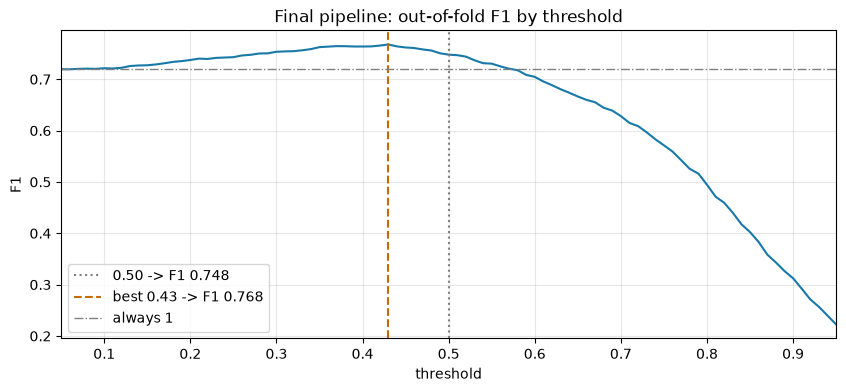

final threshold: 0.43 | honest F1 (fold 3): 0.802


In [30]:
final_oof = oofs["logistic regression + L1 selection (final)"]
covered = final_oof.notna()
FINAL_THRESHOLD, f1_curve = best_threshold(y[covered], final_oof[covered])

fig, ax = plt.subplots()
ax.plot(f1_curve.index, f1_curve.values, color=BLUE)
ax.axvline(0.5, color="grey", ls=":", label=f"0.50 -> F1 {f1_curve[0.5]:.3f}")
ax.axvline(FINAL_THRESHOLD, color=ORANGE, ls="--", label=f"best {FINAL_THRESHOLD:.2f} -> F1 {f1_curve[FINAL_THRESHOLD]:.3f}")
ax.axhline(f1_score(y[covered], np.ones(covered.sum())), color="grey", ls="-.", lw=1, label="always 1")
ax.set(title="Final pipeline: out-of-fold F1 by threshold", xlabel="threshold", ylabel="F1", xlim=(0.05, 0.95))
ax.legend()
plt.show()
print(f"final threshold: {FINAL_THRESHOLD:.2f} | honest F1 (fold 3): {honest_f1(final_oof)[0]:.3f}")

**Reading**
- **The default threshold of 0.5 would lose F1:** the best is about **0.43**. With 56% of purchases being repeats, F1 rewards predicting 1 more readily than a balanced cut.
- **The F1 curve is flat around its maximum** (roughly 0.35–0.46 within a few thousandths), so the exact value matters little; the honest F1 of 0.802 already includes the uncertainty of choosing it on earlier years.

## 4.5 Final model and predictions for `test.csv`
The final pipeline is refitted on **all** cleaned training rows (the L1 step chooses its columns again on them), predicts a probability for every test row, and the threshold of §4.4 turns it into 0/1. `ID` is kept unchanged and the file follows `sample_submission.csv`.

In [31]:
final_model = clone(final_pipeline).fit(X_full, y)
proba_test = final_model.predict_proba(X_test_full)[:, 1]
submission = pd.DataFrame({"ID": X_test_full.index, TARGET: (proba_test >= FINAL_THRESHOLD).astype(int)})

# Same columns, same IDs in the same order as the sample submission, only 0/1 labels
assert list(submission.columns) == list(sample.columns)
assert submission["ID"].reset_index(drop=True).equals(sample["ID"])
assert submission[TARGET].isin([0, 1]).all()

submission.to_csv(OUTPUT, index=False)
print(f"{len(submission)} predictions written to {OUTPUT.name}: {submission[TARGET].mean():.1%} predicted 1")
submission.head()

986 predictions written to Homework_Group41_submission.csv: 73.6% predicted 1


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


# 5. Summary <a class="anchor" id="summary"></a>
[Back to contents](#toc)

| Stage | Choice | Evidence in this notebook |
|---|---|---|
| Cleaning | drop 65 empty train rows; impossible values → missing by rule; exact identities rebuild lost values | §1.3, §2.2–2.5 |
| `clientes.csv` | not integrated | at most +0.001 ROC AUC; information already in `customer_tenure_days` (§1.8, §2.8) |
| New feature | month of purchase | 4-month repeat cycle (§1.6); largest gain (§2.8) |
| Pre-processing | median / mode imputation, signed log, robust scaling, one-hot (rare levels grouped), fitted on training rows only | §1.5, §2.7 |
| Identifier-like columns | `ID`, `customer_id`, raw date, `random_noise` never used as features | §1.7, §3.1 |
| Feature selection | L1 logistic regression (`C` = 0.05): 25 of 84 columns | +0.011 ROC AUC on 3/3 folds (§3.2) |
| Model | logistic regression | best of five algorithms (§4.3) |
| Assessment | time-ordered CV, 3 yearly blocks, 90-day gap; ROC AUC to compare, F1 to decide; threshold 0.43 | §4.1–4.4 |
| **Result** | **honest F1 0.802** (floor 0.753); **Kaggle public F1 0.804** | §4.3 |

**Main takeaways**
- The customer's **recent frequency and usual rhythm** decide most of the prediction; the calendar adds a 4-month cycle.
- **Validation that respects time** is essential: random folds would have picked a different model.
- On data of this size, **a regularised linear model with a selection step** is as good as or better than more flexible models used without tuning.